# Catcher framing with a hierarchical Bayesian model (2025 vs. 2026 ABS)

**Question:** How much does each catcher change called strikes, separate from the pitcher, batter and umpire? And did the 2026 ABS challenge system shrink the differences between catchers?

**Plan**
1. Load pitch-level Statcast (all columns) and keep **taken pitches** (called strike or ball).
2. **Difficulty model:** strike probability from location, count and handedness only, with no people (gradient boosting, out-of-fold).
3. **Run value of a strike vs. a ball** in each count, computed from Statcast's `delta_run_exp`.
4. Home-plate **umpire** for each game from the MLB Stats API.
5. **Simple baseline:** a fixed effect per catcher (plain maximum likelihood). Shows the small-sample problem.
6. **Hierarchical model (NumPyro):** random effects for catcher, pitcher, batter and umpire, partially pooled.
7. Convert to **framing runs with uncertainty**, compare the two methods, and compare **2025 vs. 2026**.

**Runs locally (VS Code).** Install once, in the same Python environment as the notebook kernel:
```
python -m pip install numpyro jax pybaseball pyarrow scikit-learn scipy pandas matplotlib requests ipykernel
```

In [1]:
import json, time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy.optimize import brentq
from scipy.special import expit, logit
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict

try:
    from IPython.display import display
except ImportError:
    display = print

PROJECT_DIR = Path.home() / "baseball" / "arsenal_transformer"
DATA_DIR = PROJECT_DIR / "data";    DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = PROJECT_DIR / "framing";  OUT_DIR.mkdir(parents=True, exist_ok=True)

SEASONS = [2025, 2026]
USE_UMPIRES = True        # fetch home-plate umpires (one API call per game, cached)
INFERENCE = "svi"         # "svi" = fast variational fit (minutes); "nuts" = full MCMC (slow, more exact)
BORDER = (0.05, 0.95)     # keep pitches whose difficulty-model strike probability is in this range
SEED = 42
print("Data folder:", DATA_DIR.resolve())

Data folder: /Users/jinzhixu/baseball/arsenal_transformer/data


## 1. Load Statcast with all columns

The files saved for the earlier notebooks only kept pitch-physics columns, so this downloads each season once with **all** columns (`statcast_full_{year}.parquet`, roughly 10–20 minutes per season) and reads only what framing needs. The full files are useful for later projects too.

In [21]:
COLS = ["game_pk", "game_date", "game_type", "pitcher", "batter", "fielder_2", "description",
        "plate_x", "plate_z", "sz_top", "sz_bot", "balls", "strikes", "stand", "p_throws",
        "delta_run_exp"]

#fielder_2 捕手的 ID(守备位置 2 = 捕手)
#description: 这一球的结果:called_strike、ball、blocked_ball、swinging_strike、foul、hit_into_play 等
#sz_top: 这位打者好球带的上沿(英尺)
#balls: 投这球前的坏球数
#strikes: 投这球前的好球数
#delta_run_exp: 这一球造成的得分期望变化(从进攻方视角) 实际的得分变化

def load_full_season(year):
    path = DATA_DIR / f"statcast_full_{year}.parquet"
    if not path.exists():
        from pybaseball import cache, statcast
        cache.enable()
        print(f"{year}: downloading all columns with pybaseball (keep VS Code open)...")
        statcast(start_dt=f"{year}-03-15", end_dt=f"{year}-10-05").to_parquet(path, index=False)
    df_ = pd.read_parquet(path, columns=COLS)
    df_["season"] = year
    print(f"{year}: {len(df_):,} pitches")
    return df_

raw = pd.concat([load_full_season(y) for y in SEASONS], ignore_index=True)

2025: 761,524 pitches
2026: 759,679 pitches


In [23]:
raw[raw['game_pk'] == 813062]

,game_pk,game_date,game_type,pitcher,batter,fielder_2,description,plate_x,plate_z,sz_top,sz_bot,balls,strikes,stand,p_throws,delta_run_exp,season
0,813062,2025-10-05,D,622554,519317,672386,swinging_strike_blocked,1.124184,0.671752,3.8,1.83,0,2,R,R,-0.178,2025
1,813062,2025-10-05,D,622554,519317,672386,swinging_strike,1.110725,1.667232,3.8,1.83,0,1,R,R,-0.057,2025
2,813062,2025-10-05,D,622554,519317,672386,foul,-0.745528,1.906816,3.8,1.83,0,0,R,R,-0.047,2025
3,813062,2025-10-05,D,622554,700250,672386,ball,0.929425,1.136583,3.661883,1.834086,3,2,L,R,0.134,2025
4,813062,2025-10-05,D,622554,700250,672386,ball,-1.21043,2.727405,3.696616,1.868632,2,2,L,R,0.057,2025
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
299,813062,2025-10-05,D,702056,592450,672386,ball,1.213639,2.307717,4.111611,1.895385,0,0,R,R,0.039,2025
300,813062,2025-10-05,D,702056,663757,672386,swinging_strike_blocked,-0.392419,1.743217,3.62,1.72,1,2,L,R,-0.189,2025
301,813062,2025-10-05,D,702056,663757,672386,swinging_strike,-0.437569,1.208753,3.62,1.72,1,1,L,R,-0.061,2025
302,813062,2025-10-05,D,702056,663757,672386,ball,-0.590057,0.220304,3.648091,1.873394,0,1,L,R,0.031,2025


**Taken pitches only.** Framing only matters when the batter doesn't swing. `blocked_ball` is a ball in the dirt the catcher blocked, so it counts as a ball. Height is normalized to each batter's zone (`0` = bottom of his zone, `1` = top), since strike zones differ by batter.

In 2026, a challenged call should appear with its final (post-challenge) result, which is what "net framing value" should use. Spot-check a few known overturned calls if you want to confirm.

In [24]:
TAKES = {"called_strike": 1, "ball": 0, "blocked_ball": 0}
tk = raw[(raw["game_type"] == "R") & raw["description"].isin(TAKES)].copy()
tk = tk.dropna(subset=["plate_x", "plate_z", "sz_top", "sz_bot", "fielder_2", "pitcher", "batter"])
tk["y"] = tk["description"].map(TAKES).astype(int)
#y is the outcome the model learns to predict: whether the umpire called the pitch a strike.
tk["z_norm"] = (tk["plate_z"] - tk["sz_bot"]) / (tk["sz_top"] - tk["sz_bot"])
tk["lhb"] = (tk["stand"] == "L").astype(int)
tk["lhp"] = (tk["p_throws"] == "L").astype(int)
tk["count"] = tk["balls"].astype(int).astype(str) + "-" + tk["strikes"].astype(int).astype(str)
for col in ["fielder_2", "pitcher", "batter"]:
    tk[col] = tk[col].astype(int)
del raw
print(f"{len(tk):,} taken pitches; strike rate {tk['y'].mean():.3f}")
display(tk.groupby("season")["y"].agg(["size", "mean"]))

740,231 taken pitches; strike rate 0.312


,size,mean
season,,
2025,368845,0.313275
2026,371386,0.311371


In [25]:
tk.head()

,game_pk,game_date,game_type,pitcher,batter,fielder_2,description,plate_x,plate_z,sz_top,...,strikes,stand,p_throws,delta_run_exp,season,y,z_norm,lhb,lhp,count
4975,776151,2025-09-28,R,669711,668670,657136,called_strike,0.567564,2.59319,3.372472,...,2,R,R,-0.16,2025,1,0.577935,0,0,0-2
4978,776151,2025-09-28,R,669711,668670,657136,called_strike,0.934337,2.571056,3.3999,...,0,R,R,-0.033,2025,1,0.542416,0,0,0-0
4980,776151,2025-09-28,R,669711,628451,657136,ball,1.050086,2.50256,3.140002,...,2,R,R,0.044,2025,0,0.602451,0,0,1-2
4983,776151,2025-09-28,R,669711,628451,657136,ball,1.194208,2.929027,3.093423,...,2,R,R,0.01,2025,0,0.892223,0,0,0-2
4985,776151,2025-09-28,R,669711,628451,657136,called_strike,-0.605839,1.962363,3.460472,...,0,R,R,-0.04,2025,1,0.135985,0,0,0-0


## 2. Difficulty model (location, count, handedness; no people)

Predictions are **out-of-fold**, grouped by game, so a pitch's difficulty never comes from a model that saw that pitch. The model is fit per season, because the called zone itself may have shifted under ABS.

Borderline pitches: 181,224 of 740,231 takes


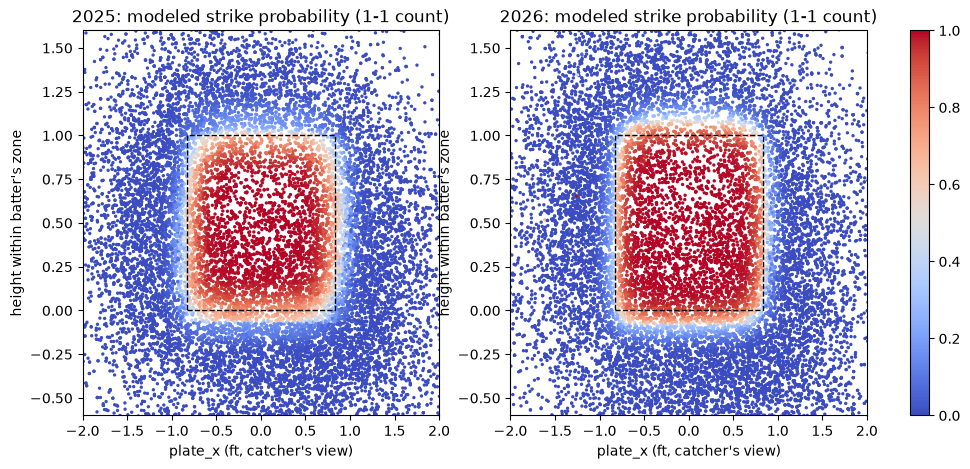

In [8]:
#The classifier learns P(y = 1 | location, count, handedness). 
# In plain terms: “how often does a pitch here, in this count, with these hands, get called a strike?” 
# It uses only the pitch, not the catcher, so it describes a league-average catcher and umpire.

#y is the outcome the model learns to predict: whether the umpire called the pitch a strike.

FEATS = ["plate_x", "z_norm", "balls", "strikes", "lhb", "lhp"]
tk["p_base"] = np.nan
for s in SEASONS:
    m = tk["season"] == s
    clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, max_leaf_nodes=31,
                                         random_state=SEED)
    tk.loc[m, "p_base"] = cross_val_predict(
        clf, tk.loc[m, FEATS], tk.loc[m, "y"], groups=tk.loc[m, "game_pk"],
        cv=GroupKFold(n_splits=5), method="predict_proba")[:, 1]
tk["offset"] = logit(tk["p_base"].clip(1e-4, 1 - 1e-4))

border = tk[tk["p_base"].between(*BORDER)].copy()
print(f"Borderline pitches: {len(border):,} of {len(tk):,} takes")

fig, axes = plt.subplots(1, len(SEASONS), figsize=(5.5 * len(SEASONS), 5), squeeze=False)
for ax, s in zip(axes[0], SEASONS):
    d = tk[(tk["season"] == s) & (tk["count"] == "1-1")].sample(n=20_000, random_state=SEED, replace=True)
    sc_ = ax.scatter(d["plate_x"], d["z_norm"], c=d["p_base"], s=2, cmap="coolwarm", vmin=0, vmax=1)
    ax.add_patch(plt.Rectangle((-0.83, 0), 1.66, 1, fill=False, ls="--"))
    ax.set_xlim(-2, 2); ax.set_ylim(-0.6, 1.6)
    ax.set_title(f"{s}: modeled strike probability (1-1 count)")
    ax.set_xlabel("plate_x (ft, catcher's view)"); ax.set_ylabel("height within batter's zone")
fig.colorbar(sc_, ax=axes[0].tolist(), fraction=0.03)
plt.show()

## 3. Run value of a called strike vs. a ball, by count

`delta_run_exp` is each pitch's change in run expectancy for the batting team. For each count, the average after a called strike minus the average after a ball is the cost (for the batter) of one strike call. Its negative is what an extra framed strike saves the defense.

In [9]:
rv = (tk.dropna(subset=["delta_run_exp"])
        .groupby(["season", "count", "y"])["delta_run_exp"].mean().unstack("y"))
rv["runs_per_strike"] = -(rv[1] - rv[0])          # runs saved by the defense per extra strike
display(rv["runs_per_strike"].unstack("season").round(3))
border = border.merge(rv["runs_per_strike"].reset_index(), on=["season", "count"], how="left")
border["runs_per_strike"] = border["runs_per_strike"].fillna(rv["runs_per_strike"].median())

season,2025,2026
count,,
0-0,0.076,0.079
0-1,0.081,0.086
0-2,0.189,0.19
1-0,0.111,0.116
1-1,0.113,0.119
1-2,0.227,0.233
2-0,0.18,0.177
2-1,0.182,0.184
2-2,0.324,0.326


## 4. Home-plate umpires (MLB Stats API)

One request per game, run in parallel and cached to `framing/umpires.parquet`. Set `USE_UMPIRES = False` to skip (the model then has no umpire effect).

In [10]:
UMP_FILE = OUT_DIR / "umpires.parquet"

def hp_umpire(pk):
    try:
        r = requests.get(f"https://statsapi.mlb.com/api/v1/game/{pk}/boxscore", timeout=30)
        r.raise_for_status()
        for o in r.json().get("officials", []):
            if o.get("officialType") == "Home Plate":
                return {"game_pk": pk, "umpire": o["official"]["id"], "umpire_name": o["official"]["fullName"]}
    except Exception as e:
        print("  failed", pk, e)
    return {"game_pk": pk, "umpire": np.nan, "umpire_name": None}

if USE_UMPIRES:
    umps = pd.read_parquet(UMP_FILE) if UMP_FILE.exists() else pd.DataFrame(columns=["game_pk", "umpire", "umpire_name"])
    todo = sorted(set(border["game_pk"]) - set(umps.loc[umps["umpire"].notna(), "game_pk"]))
    print(f"{len(todo):,} games to look up")
    for i in range(0, len(todo), 400):
        with ThreadPoolExecutor(max_workers=8) as ex:
            new = pd.DataFrame(list(ex.map(hp_umpire, todo[i:i + 400])))
        umps = pd.concat([umps, new]).drop_duplicates("game_pk", keep="last")
        umps.to_parquet(UMP_FILE, index=False)
        print(f"  {min(i + 400, len(todo)):,}/{len(todo):,}")
    border = border.merge(umps[["game_pk", "umpire"]], on="game_pk", how="left")
    print(f"Pitches without an umpire (dropped): {border['umpire'].isna().sum():,}")
    border = border.dropna(subset=["umpire"])
    border["umpire"] = border["umpire"].astype(int)

4,859 games to look up
  400/4,859
  800/4,859
  1,200/4,859
  1,600/4,859
  2,000/4,859
  2,400/4,859
  2,800/4,859
  3,200/4,859
  3,600/4,859
  4,000/4,859
  4,400/4,859
  4,800/4,859
  4,859/4,859
Pitches without an umpire (dropped): 0


In [11]:
# Catcher names (optional, needs internet)
try:
    from pybaseball import playerid_reverse_lookup
    lk = playerid_reverse_lookup(sorted(border["fielder_2"].unique().tolist()), key_type="mlbam")
    NAMES = dict(zip(lk["key_mlbam"], (lk["name_first"] + " " + lk["name_last"]).str.title()))
except Exception as e:
    print("Name lookup failed, using IDs:", e)
    NAMES = {}
name = lambda pid: NAMES.get(int(pid), str(int(pid)))

## 5. Simple baseline: a fixed effect per catcher

For each catcher alone, find the shift `a` on the log-odds scale that makes predicted strikes match his actual strikes:
`sum(y − sigmoid(offset + a)) = 0`. No sharing of information between catchers, so a catcher with very few pitches can get an extreme value.

**Runs** for any effect `a`: sum over his pitches of `[sigmoid(offset + a) − sigmoid(offset)] × runs_per_strike`.

In [ ]:
#Expected strikes = sum of sigmoid(offset) over his pitches: what an average catcher would get.
#Actual strikes = sum of y: what he actually got.

#a is a shift on the log-odds scale that applies to all his pitches:
#P(strike) = sigmoid(offset + a)
# a = 0: he’s exactly average.
# a > 0: every pitch is a bit more likely to be called a strike with him catching.
# a < 0: less likely.

**The equation: sum(y − sigmoid(offset + a)) = 0**

It means: choose a so that predicted strikes equal actual strikes.

Example: a catcher received 1,000 borderline pitches.
The difficulty model expects 480 strikes (average catcher).
He actually got 520.    
Solve for a: try a = 0.1 and the predicted total rises to about 500; try a = 0.2 and it’s about 520. So a ≈ 0.2.     

sigmoid(offset + a): his chance of a strike.   
sigmoid(offset): an average catcher’s chance.   
The difference is the extra strike probability he added on that pitch, e.g. 0.55 − 0.50 = 0.05 of a strike.     
     
Summed over all pitches, that’s extra strikes: about 40 in the example (520 − 480). Times runs_per_strike (about 0.125), that’s ≈ +5 runs saved compared with an average catcher.

**The weakness, and why the Bayesian model exists**

“No sharing of information between catchers” means a backup with 50 pitches is estimated from those 50 alone. If he happened to get 8 lucky calls, he gets a huge a, and his framing looks elite (or terrible) purely from noise.

The Bayesian hierarchical model in the next section ***fixes this with partial pooling***. Each catcher’s effect is pulled toward the league average (0), and the pull is stronger the fewer pitches he has:

![](image.png)

In [26]:
def fixed_effect(off, y, bound=4.0):
    f = lambda a: np.sum(y - expit(off + a))
    lo, hi = f(-bound), f(bound)
    if lo * hi > 0:                                   # all strikes or all balls -> boundary
        return bound if lo > 0 else -bound
    return brentq(f, -bound, bound)

def effect_runs(off, a, rps):
    return np.sum((expit(off + a) - expit(off)) * rps)

def fixed_table(d):
    rows = []
    for c, g in d.groupby("fielder_2"):
        a = fixed_effect(g["offset"].to_numpy(), g["y"].to_numpy())
        rows.append({"catcher": c, "pitches": len(g),
                     "extra_strikes_naive": (g["y"] - g["p_base"]).sum(),
                     "fixed_logit": a,
                     "fixed_runs": effect_runs(g["offset"].to_numpy(), a, g["runs_per_strike"].to_numpy())})
    return pd.DataFrame(rows)

FIXED = {s: fixed_table(border[border["season"] == s]) for s in SEASONS}
s0 = SEASONS[-1]
print(f"{s0}: catchers with the most extreme fixed effects")
display(FIXED[s0].assign(name=FIXED[s0]["catcher"].map(name))
        .reindex(FIXED[s0]["fixed_logit"].abs().sort_values(ascending=False).index).head(10).round(3))

2026: catchers with the most extreme fixed effects


,catcher,pitches,extra_strikes_naive,fixed_logit,fixed_runs,name
69,676566,25,-4.310,-1.301,-0.518,Shawn Ross
30,650968,179,-19.793,-0.790,-2.675,Yohel Pozo
25,642020,89,-10.177,-0.771,-1.336,Chuckie Robinson
93,691620,13,-1.558,-0.696,-0.248,Jeferson Quero
13,605244,78,6.298,0.577,0.769,Aramis Garcia
83,683079,17,-1.368,-0.546,-0.201,Omar Martinez
108,805672,42,2.929,0.494,0.329,Collin Price
67,675448,15,-1.097,-0.465,-0.099,Blake Hunt
29,645305,498,33.970,0.435,4.483,Ali Sánchez
23,641598,461,-29.490,-0.425,-4.230,Mitch Garver


## 6. Hierarchical model (NumPyro)

$$\text{logit}\,P(\text{strike}) = \text{offset} + b_0 + \text{catcher}_c + \text{pitcher}_p + \text{batter}_b + \text{umpire}_u$$

Each group's effects come from a normal distribution whose spread (`sigma_catcher`, etc.) is **learned from the data**. A catcher with few pitches gets pulled toward 0 (average) unless his data strongly says otherwise. `sigma_catcher` itself answers "how much do catchers really differ?", which is the number to compare between 2025 and 2026.

Effects use the **non-centered** form (`effect = sigma × z`, `z ~ Normal(0, 1)`), which samples much better.

- `INFERENCE = "svi"`: stochastic variational inference with a mean-field normal approximation. A few minutes on a laptop. Intervals can be slightly too narrow.
- `INFERENCE = "nuts"`: full MCMC. More exact, but with ~100k+ pitches expect tens of minutes per season on a CPU.

In [ ]:
#logit, log(p/(1−p)),probability → log-odds
#sigmoid, 1/1+exp(-x), log-odds → probability   
# 
# b0: season-wide correction to the offset

In [ ]:
#Why split it into sigma × z?

#You could write it directly as effect ~ Normal(0, sigma_catcher).
#  It’s the same model mathematically. But when sigma and the effects are sampled together, 
#they form a funnel-shaped space that NUTS explores badly: when sigma is small, all effects are squeezed near 0. 
# Sampling z ~ Normal(0, 1) separately and multiplying removes the funnel. 
#This is the non-centered parameterization, the same trick used in your fatigue model.

In [14]:
import jax
import jax.numpy as jnp
import numpyro
import numpyro.diagnostics
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, SVI, Trace_ELBO
from numpyro.infer.autoguide import AutoNormal

#USE_UMPIRES True
GROUPS = ["catcher", "pitcher", "batter"] + (["umpire"] if USE_UMPIRES else [])
COLMAP = {"catcher": "fielder_2", "pitcher": "pitcher", "batter": "batter", "umpire": "umpire"}

def framing_model(offset, idx, sizes, y=None):
    b0 = numpyro.sample("b0", dist.Normal(0.0, 0.5))
    eta = offset + b0
    for g in GROUPS:
        sigma = numpyro.sample(f"sigma_{g}", dist.HalfNormal(0.3))
        with numpyro.plate(f"{g}_plate", sizes[g]):
            z = numpyro.sample(f"z_{g}", dist.Normal(0.0, 1.0))
        eta = eta + sigma * z[idx[g]]
        #sigma_catcher * z_catcher[idx["catcher"]]
        #sigma_pitcher * z_pitcher[idx["pitcher"]]
        #sigma_batter * z_batter[idx["batter"]]
        #sigma_umpire * z_umpire[idx["umpire"]]
        
        #sigma_catcher: how much catchers differ
        #z_catcher: each catcher’s standardized score
        #Prior Normal(0, 1): a standard normal. So z is “how many standard deviations above or below average this catcher is”.
        #z: +2.0: elite framer, 2 SD above average; −1.0:1 SD below average
    with numpyro.plate("obs", offset.shape[0]):
        numpyro.sample("y", dist.Bernoulli(logits=eta), obs=y)

def fit_season(d, steps=4000, draws=1000):
    codes, uniques = {}, {}
    for g in GROUPS:
        codes[g], uniques[g] = pd.factorize(d[COLMAP[g]])
    args = dict(offset=jnp.asarray(d["offset"].to_numpy(), dtype=jnp.float32),
                idx={g: jnp.asarray(codes[g]) for g in GROUPS},
                sizes={g: len(uniques[g]) for g in GROUPS})
    y = jnp.asarray(d["y"].to_numpy())
    key = jax.random.PRNGKey(SEED)
    t0 = time.time()
    if INFERENCE == "svi":
        guide = AutoNormal(framing_model)
        svi = SVI(framing_model, guide, numpyro.optim.Adam(step_size=0.01), Trace_ELBO())
        res = svi.run(key, steps, **args, y=y, progress_bar=True)
        post = guide.sample_posterior(jax.random.PRNGKey(SEED + 1), res.params, sample_shape=(draws,))
        losses = np.asarray(res.losses)
    else:
        mcmc = MCMC(NUTS(framing_model, target_accept_prob=0.85), num_warmup=500, num_samples=draws // 2,
                    num_chains=1, progress_bar=True)
        mcmc.run(key, **args, y=y)
        grouped = mcmc.get_samples(group_by_chain=True)
        numpyro.diagnostics.print_summary(               # convergence check on the key parameters
            {k: v for k, v in grouped.items() if k.startswith("sigma") or k == "b0"}, prob=0.9)
        post = mcmc.get_samples()
        losses = None
    print(f"  fit in {(time.time() - t0) / 60:.1f} min")
    post = {k: np.asarray(v) for k, v in post.items()}
    eff = {g: post[f"sigma_{g}"][:, None] * post[f"z_{g}"] for g in GROUPS}   # draws x levels
    return dict(post=post, eff=eff, codes=codes, uniques=uniques, losses=losses)

FITS = {}
for s in SEASONS:
    print(f"Fitting {s} ({INFERENCE})...")
    FITS[s] = fit_season(border[border["season"] == s].reset_index(drop=True))

Fitting 2025 (svi)...


100%|██████████| 4000/4000 [00:06<00:00, 654.58it/s, init loss: 62099.0703, avg. loss [3801-4000]: 47288.9297]


  fit in 0.2 min
Fitting 2026 (svi)...


100%|██████████| 4000/4000 [00:05<00:00, 697.57it/s, init loss: 48321.8203, avg. loss [3801-4000]: 35791.8828]


  fit in 0.2 min


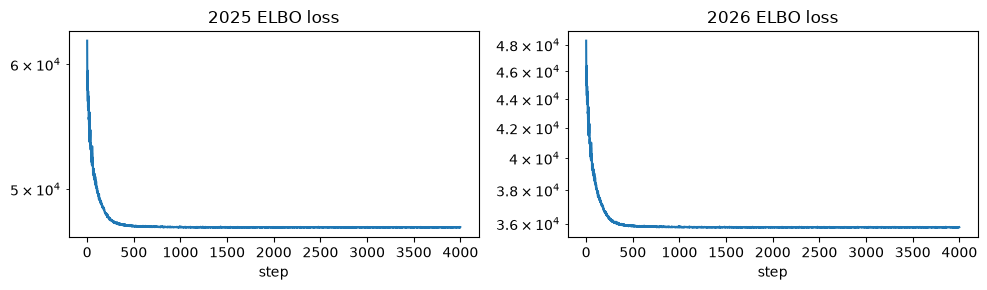

mean            5%           95%       
season    2025   2026   2025   2026   2025   2026
group                                            
batter   0.227  0.191  0.213  0.175  0.243  0.208
catcher  0.148  0.165  0.136  0.150  0.160  0.182
pitcher  0.170  0.156  0.158  0.142  0.183  0.171
umpire   0.182  0.144  0.167  0.128  0.197  0.161

In [15]:
if INFERENCE == "svi": # check the optimizer converged
    fig, axes = plt.subplots(1, len(SEASONS), figsize=(5 * len(SEASONS), 3), squeeze=False)
    for ax, s in zip(axes[0], SEASONS):
        ax.plot(FITS[s]["losses"]); ax.set_yscale("log"); ax.set_title(f"{s} ELBO loss"); ax.set_xlabel("step")
    plt.tight_layout(); plt.show()

# Spread of each group's effects (log-odds scale): who matters most for a called strike?
rows = []
for s in SEASONS:
    for g in GROUPS:
        v = FITS[s]["post"][f"sigma_{g}"]
        rows.append({"season": s, "group": g, "mean": v.mean(),
                     "5%": np.quantile(v, 0.05), "95%": np.quantile(v, 0.95)})
display(pd.DataFrame(rows).pivot(index="group", columns="season").round(3))

In [ ]:
#posterior mean of sigma_catcher for each season, with its 90% interval.

## 7. Framing runs with uncertainty

For each posterior draw of a catcher's effect `e`, holding everyone else at their posterior means:
runs = sum over his pitches of `[sigmoid(eta₀ + e) − sigmoid(eta₀)] × runs_per_strike`,
where `eta₀` is the log-odds without the catcher. This gives a full distribution of runs per catcher.

In [ ]:
# How the runs are computed (eta0)

# For each of his pitches, the function builds the strike log-odds without the catcher:

# eta0 = offset + b0 + pitcher effect + batter effect + umpire effect

# Each of those uses its posterior mean. Then, for every posterior draw of his catcher effect e:

# runs = sum over his pitches of [sigmoid(eta0 + e) − sigmoid(eta0)] × runs_per_strike

# That’s “how many extra strikes he added, compared with an average catcher with the same pitches, pitchers, batters and umpires, 
# converted to runs.” Doing it for every draw gives a whole distribution of runs per catcher, not just one number. 
# That distribution is what the interval columns summarize.

In [16]:
def framing_runs(s):
    d = border[border["season"] == s].reset_index(drop=True)
    F = FITS[s]
    eta0 = d["offset"].to_numpy() + F["post"]["b0"].mean()
    for g in GROUPS:
        if g != "catcher":
            eta0 = eta0 + F["eff"][g].mean(0)[F["codes"][g]]
    rps = d["runs_per_strike"].to_numpy()
    rows, draws = [], {}
    for k, c in enumerate(F["uniques"]["catcher"]):
        m = F["codes"]["catcher"] == k
        e = F["eff"]["catcher"][:, k][:, None]                        # draws x 1
        r = ((expit(eta0[m][None, :] + e) - expit(eta0[m][None, :])) * rps[m][None, :]).sum(1)
        draws[c] = r
        rows.append({"catcher": c, "name": name(c), "pitches": int(m.sum()),
                     "runs": r.mean(), "5%": np.quantile(r, 0.05), "95%": np.quantile(r, 0.95),
                     "P(above avg)": (r > 0).mean()})
    tab = pd.DataFrame(rows).merge(FIXED[s][["catcher", "fixed_runs", "fixed_logit"]], on="catcher")
    tab["hier_logit"] = F["eff"]["catcher"].mean(0)[[list(F["uniques"]["catcher"]).index(c) for c in tab["catcher"]]]
    return tab.sort_values("runs", ascending=False).reset_index(drop=True), draws

RUNS, DRAWS = {}, {}
for s in SEASONS:
    RUNS[s], DRAWS[s] = framing_runs(s)
    RUNS[s].to_csv(OUT_DIR / f"framing_runs_{s}.csv", index=False)
    print(f"\n{s}: top 10 framers")
    display(RUNS[s].head(10).round(2))
    print(f"{s}: bottom 5")
    display(RUNS[s].tail(5).round(2))

#runs: framing runs: posterior mean of runs saved vs. an average catcher
#P(above avg):  share of draws with runs > 0, Probability he’s better than average. 0.99 means near-certain; 0.6 means barely better than a coin flip.

#fixed_runs: runs from the fixed-effect baseline (no pooling, no pitcher/batter/umpire adjustment)
#fixed_logit: the baseline’s effect a on the log-odds scale
#hier_logit: the hierarchical model’s catcher effect, posterior mean of sigma × z: the counterpart of fixed_logit, after shrinkage


2025: top 10 framers


,catcher,name,pitches,runs,5%,95%,P(above avg),fixed_runs,fixed_logit,hier_logit
0,672275,Patrick Bailey,2500,19.62,15.33,23.88,1.00,26.04,0.50,0.38
1,672386,Alejandro Kirk,2330,11.63,7.56,15.66,1.00,16.95,0.35,0.24
2,595978,Austin Hedges,1144,9.62,6.95,12.29,1.00,11.48,0.48,0.40
3,669224,Austin Wells,2359,8.35,4.33,12.41,1.00,10.94,0.23,0.18
4,665966,Carlos Narváez,2269,5.76,1.87,9.69,1.00,5.04,0.11,0.13
5,663728,Cal Raleigh,2446,5.32,1.38,9.37,0.98,5.19,0.10,0.11
6,693307,Dillon Dingler,2409,4.52,0.60,8.79,0.97,6.63,0.14,0.09
7,624431,Jose Trevino,1691,3.78,0.36,7.20,0.96,2.79,0.08,0.11
8,620443,Luis Torrens,1574,3.74,0.70,6.90,0.98,3.39,0.11,0.12
9,686780,Pedro Pagés,2222,3.47,-0.18,6.89,0.94,3.66,0.08,0.08


2025: bottom 5


,catcher,name,pitches,runs,5%,95%,P(above avg),fixed_runs,fixed_logit,hier_logit
106,592663,J. T. Realmuto,2867,-6.63,-11.19,-2.20,0.01,-7.99,-0.14,-0.12
107,656180,Riley Adams,1697,-7.22,-10.21,-4.29,0.00,-10.30,-0.30,-0.22
108,681351,Logan O'Hoppe,2160,-7.40,-10.69,-4.11,0.00,-10.53,-0.24,-0.17
109,700337,Edgar Quero,1374,-10.00,-12.98,-6.83,0.00,-15.09,-0.53,-0.35
110,669257,Will Smith,2160,-11.62,-15.58,-7.79,0.00,-13.51,-0.29,-0.25



2026: top 10 framers


,catcher,name,pitches,runs,5%,95%,P(above avg),fixed_runs,fixed_logit,hier_logit
0,693307,Dillon Dingler,1823,7.95,4.08,12.06,1.0,6.77,0.19,0.23
1,669224,Austin Wells,1692,5.55,2.38,8.55,1.0,6.74,0.20,0.16
2,672386,Alejandro Kirk,1078,5.51,2.91,8.22,1.0,7.03,0.34,0.27
3,605170,Víctor Caratini,1164,5.32,2.50,8.21,1.0,5.65,0.24,0.22
4,672275,Patrick Bailey,1462,5.17,2.00,8.28,1.0,4.64,0.16,0.18
5,678218,Brandon Valenzuela,1087,5.10,2.55,7.69,1.0,5.91,0.27,0.23
6,668939,Adley Rutschman,1251,5.01,1.91,8.22,1.0,4.37,0.18,0.21
7,691788,Joe Mack,1330,4.94,2.44,7.43,1.0,4.91,0.19,0.19
8,620443,Luis Torrens,1178,4.78,2.15,7.62,1.0,5.24,0.23,0.21
9,623168,Tyler Heineman,928,3.94,1.70,6.26,1.0,4.37,0.23,0.21


2026: bottom 5


,catcher,name,pitches,runs,5%,95%,P(above avg),fixed_runs,fixed_logit,hier_logit
105,643376,Danny Jansen,906,-4.75,-6.87,-2.59,0.00,-6.75,-0.40,-0.28
106,694212,Samuel Basallo,897,-4.94,-7.42,-2.68,0.00,-6.96,-0.39,-0.28
107,663886,Tyler Stephenson,1793,-5.50,-9.22,-1.86,0.01,-6.91,-0.20,-0.16
108,657136,Connor Wong,1017,-5.69,-8.27,-3.25,0.00,-7.79,-0.39,-0.29
109,681351,Logan O'Hoppe,1177,-6.33,-9.23,-3.52,0.00,-8.90,-0.37,-0.26


### Why the hierarchical model: shrinkage

Each line connects a catcher's **fixed-effect** estimate (gray) to his **hierarchical** estimate (red). Catchers with few borderline pitches get pulled strongly toward 0; everyday catchers barely move.

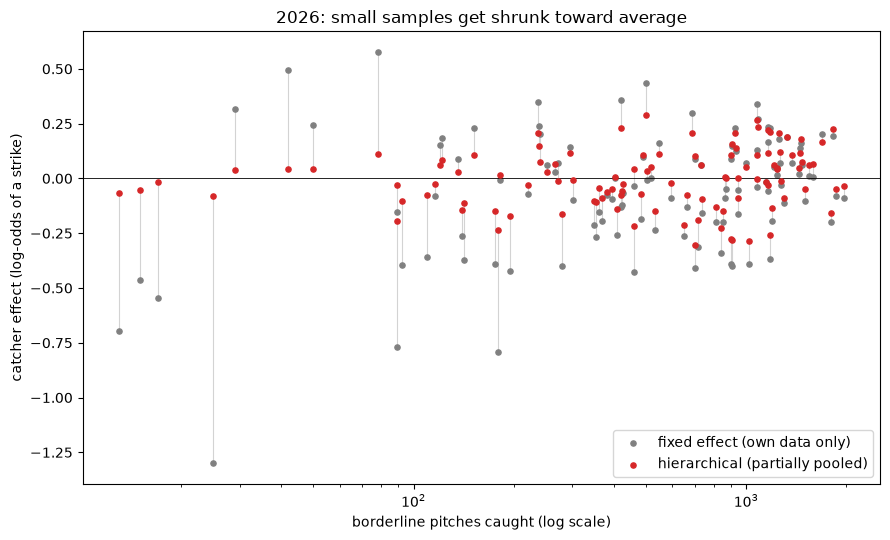

In [17]:
s = SEASONS[-1]
t = RUNS[s]
fig, ax = plt.subplots(figsize=(9, 5.5))
for _, r in t.iterrows():
    ax.plot([r["pitches"]] * 2, [r["fixed_logit"], r["hier_logit"]], color="lightgray", lw=0.8, zorder=1)
ax.scatter(t["pitches"], t["fixed_logit"], s=14, color="gray", label="fixed effect (own data only)", zorder=2)
ax.scatter(t["pitches"], t["hier_logit"], s=14, color="tab:red", label="hierarchical (partially pooled)", zorder=3)
ax.axhline(0, color="black", lw=0.6)
ax.set_xscale("log"); ax.set_xlabel("borderline pitches caught (log scale)")
ax.set_ylabel("catcher effect (log-odds of a strike)")
ax.set_title(f"{s}: small samples get shrunk toward average"); ax.legend()
plt.tight_layout(); plt.show()

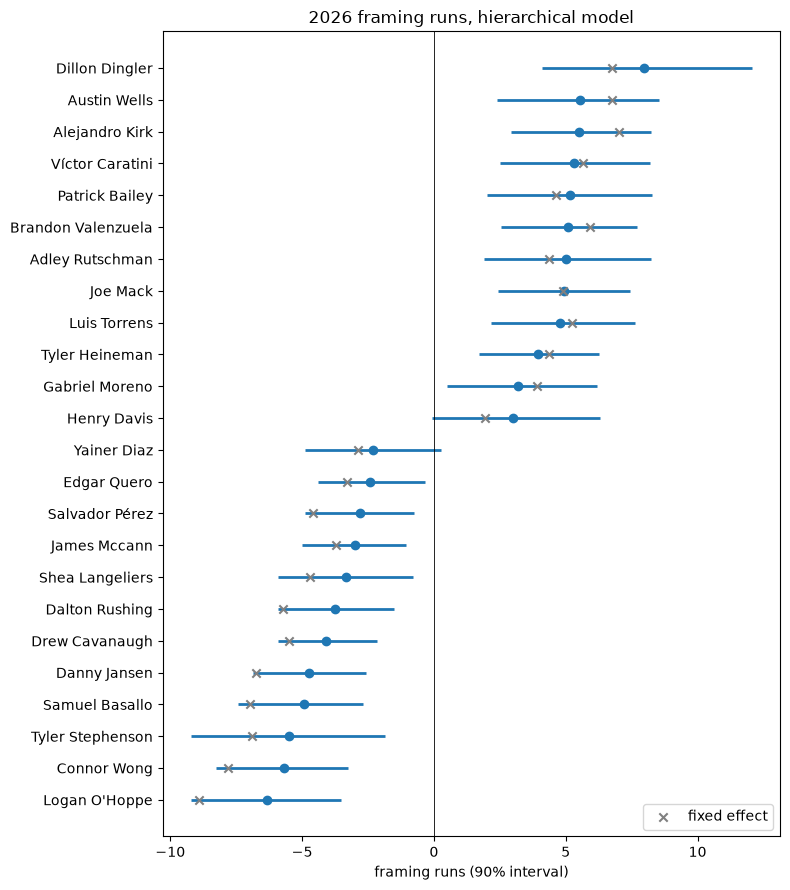

In [18]:
# Forest plot: top and bottom 12 everyday catchers (enough pitches to matter)
s = SEASONS[-1]
t = RUNS[s][RUNS[s]["pitches"] >= RUNS[s]["pitches"].quantile(0.5)]
show = pd.concat([t.head(12), t.tail(12)]).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 9))
yy = np.arange(len(show))
ax.hlines(yy, show["5%"], show["95%"], color="tab:blue", lw=2)
ax.scatter(show["runs"], yy, color="tab:blue", zorder=3)
ax.scatter(show["fixed_runs"], yy, color="gray", marker="x", zorder=3, label="fixed effect")
ax.axvline(0, color="black", lw=0.6)
ax.set_yticks(yy, show["name"]); ax.set_xlabel("framing runs (90% interval)")
ax.set_title(f"{s} framing runs, hierarchical model"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 8. Did ABS shrink framing? 2025 vs. 2026

Three views:
1. **`sigma_catcher`**: how much catchers differ in log-odds of a strike. If ABS reduced framing's impact, the 2026 distribution should sit lower.
2. **Spread in runs:** the standard deviation of catcher framing runs, per 1,000 borderline pitches.
3. **Same catchers, both years:** who lost the most.

Caveat: some change would happen anyway through normal year-to-year variation, and catchers can adapt their technique. A drop in the spread is suggestive, not proof of ABS's effect.

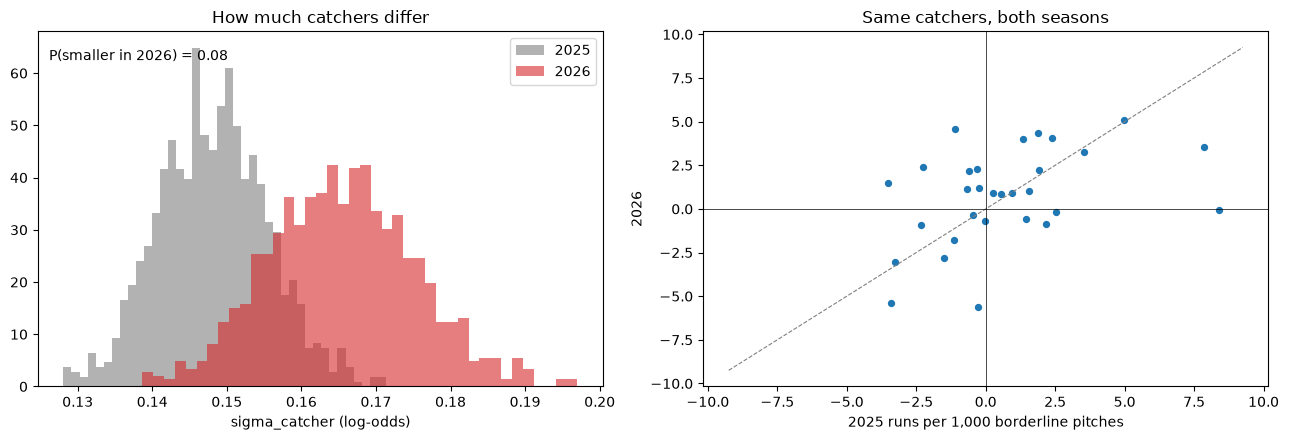

SD of framing runs per 1,000 borderline pitches: {2025: np.float64(2.96), 2026: np.float64(2.7)}
Biggest drops:


,catcher,name,runs_2025,pitches_2025,runs_2026,pitches_2026,per1000_2025,per1000_2026,change
2,595978,Austin Hedges,9.62,1144,-0.05,1075,8.41,-0.04,-8.45
58,657136,Connor Wong,-0.29,1083,-5.69,1017,-0.27,-5.60,-5.33
0,672275,Patrick Bailey,19.62,2500,5.17,1462,7.85,3.54,-4.31
5,663728,Cal Raleigh,5.32,2446,-1.33,1502,2.17,-0.89,-3.06
4,665966,Carlos Narváez,5.76,2269,-0.24,1272,2.54,-0.19,-2.73
15,663743,Nick Fortes,2.01,1378,-0.65,1159,1.46,-0.56,-2.01
87,681351,Logan O'Hoppe,-7.40,2160,-6.33,1177,-3.43,-5.38,-1.95
81,669127,Shea Langeliers,-3.53,2336,-3.33,1192,-1.51,-2.80,-1.28


In [19]:
if len(SEASONS) >= 2:
    a, b = SEASONS[0], SEASONS[-1]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for s, col in [(a, "tab:gray"), (b, "tab:red")]:
        axes[0].hist(FITS[s]["post"]["sigma_catcher"], bins=40, alpha=0.6, color=col, label=str(s), density=True)
    axes[0].set_xlabel("sigma_catcher (log-odds)"); axes[0].set_title("How much catchers differ"); axes[0].legend()
    p_drop = (FITS[b]["post"]["sigma_catcher"][:, None] < FITS[a]["post"]["sigma_catcher"][None, :]).mean()
    axes[0].text(0.02, 0.95, f"P(smaller in {b}) = {p_drop:.2f}", transform=axes[0].transAxes, va="top")

    both = RUNS[a][["catcher", "name", "runs", "pitches"]].merge(
        RUNS[b][["catcher", "runs", "pitches"]], on="catcher", suffixes=(f"_{a}", f"_{b}"))
    for s in (a, b):
        both[f"per1000_{s}"] = both[f"runs_{s}"] / both[f"pitches_{s}"] * 1000
    both = both[(both[f"pitches_{a}"] >= 1000) & (both[f"pitches_{b}"] >= 1000)]
    axes[1].scatter(both[f"per1000_{a}"], both[f"per1000_{b}"], s=18)
    lim = np.abs(both[[f"per1000_{a}", f"per1000_{b}"]].to_numpy()).max() * 1.1
    axes[1].plot([-lim, lim], [-lim, lim], ls="--", color="gray", lw=0.8)
    axes[1].axhline(0, color="black", lw=0.5); axes[1].axvline(0, color="black", lw=0.5)
    axes[1].set_xlabel(f"{a} runs per 1,000 borderline pitches"); axes[1].set_ylabel(f"{b}")
    axes[1].set_title("Same catchers, both seasons")
    plt.tight_layout(); plt.show()

    spread = {s: (RUNS[s]["runs"] / RUNS[s]["pitches"] * 1000)[RUNS[s]["pitches"] >= 1000].std() for s in (a, b)}
    print("SD of framing runs per 1,000 borderline pitches:", {k: round(v, 2) for k, v in spread.items()})
    both["change"] = both[f"per1000_{b}"] - both[f"per1000_{a}"]
    print("Biggest drops:"); display(both.sort_values("change").head(8).round(2))

In [34]:
r = both[["per1000_2025", "per1000_2026"]].corr().iloc[0, 1]
print(f"Year-to-year correlation of framing runs per 1,000 borderline pitches: r = {r:.2f} (n = {len(both)} catchers)")

Year-to-year correlation of framing runs per 1,000 borderline pitches: r = 0.42 (n = 30 catchers)


In [ ]:
#Left Barplot of "How much catchers differ” (σ_catcher posterior)"
#P(smaller in 2026) = 0.08: only an 8% chance that catchers differ less in 2026.
# On this scale, the data point the other way: a 92% chance the spread is larger.

#Right: “Same catchers, both seasons”
#Each dot is a catcher; x = 2025 runs per 1,000 borderline pitches, y = 2026. 
#The dashed line is “same value both years”.

In [38]:
savant_data = pd.read_csv("catcher-framing_savant.csv")
savant_data.head(50)

sav = savant_data.copy()
sav["savant_per1000"] = sav["rv_tot"] / sav["pitches"] * 1000

cmp = (RUNS[2026][["catcher", "name", "runs", "pitches"]]
         .merge(sav[["id", "rv_tot", "pitches", "savant_per1000"]],
                left_on="catcher", right_on="id", suffixes=("_model", "_savant")))
cmp["model_per1000"] = cmp["runs"] / cmp["pitches_model"] * 1000

print(f"n = {len(cmp)} catchers")
print("Totals   (runs vs rv_tot):          r =", round(cmp["runs"].corr(cmp["rv_tot"]), 2))
print("Rates    (per 1,000 vs per 1,000):  r =", round(cmp["model_per1000"].corr(cmp["savant_per1000"]), 2))
print("Rank agreement (Spearman, totals):  ρ =", round(cmp["runs"].corr(cmp["rv_tot"], method="spearman"), 2))
#rv_tot: total framing runs: runs saved by getting extra strikes. Positive = good.
#pct_tot: his overall strike rate in the shadow zone: % of those takes called strikes

n = 56 catchers
Totals   (runs vs rv_tot):          r = 0.92
Rates    (per 1,000 vs per 1,000):  r = 0.92
Rank agreement (Spearman, totals):  ρ = 0.91


In [44]:
print("Model catchers:", RUNS[2026]["catcher"].nunique())
print("Savant catchers:", savant_data["id"].nunique())

Model catchers: 110
Savant catchers: 56


In [45]:
cmp.columns

Index(['catcher', 'name', 'runs', 'pitches_model', 'id', 'rv_tot',
       'pitches_savant', 'savant_per1000', 'model_per1000'],
      dtype='object')

In [46]:
cmp[['name','pitches_savant','pitches_model','rv_tot','runs','savant_per1000', 'model_per1000']]

,name,pitches_savant,pitches_model,rv_tot,runs,savant_per1000,model_per1000
0,Dillon Dingler,8377,1823,8.869311,7.950677,1.058769,4.361315
1,Austin Wells,8055,1692,6.605748,5.545461,0.820080,3.277459
2,Alejandro Kirk,5350,1078,7.026094,5.507463,1.313289,5.108964
3,Víctor Caratini,5539,1164,2.632763,5.315488,0.475314,4.566570
4,Patrick Bailey,7174,1462,4.571497,5.172653,0.637231,3.538067
5,Brandon Valenzuela,5373,1087,8.263493,5.100738,1.537966,4.692491
6,Adley Rutschman,5726,1251,6.383717,5.005276,1.114865,4.001020
7,Joe Mack,6616,1330,5.062399,4.941558,0.765175,3.715457
8,Luis Torrens,5674,1178,5.389079,4.775497,0.949785,4.053902
9,Tyler Heineman,4506,928,5.841753,3.939769,1.296439,4.245441


In [42]:
sav[['name',"rv_tot", "pct_tot","pitches", "savant_per1000"]]

,name,rv_tot,pct_tot,pitches,savant_per1000
0,"Rutschman, Adley",6.383717,0.467402,5726,1.114865
1,"Narváez, Carlos",1.986683,0.462494,6128,0.324198
2,"Amaya, Miguel",1.318838,0.479813,4693,0.281022
3,"Moreno, Gabriel",5.046773,0.468909,7065,0.714334
4,"Kelly, Carson",0.958839,0.457399,7179,0.133562
5,"Dingler, Dillon",8.869311,0.482200,8377,1.058769
6,"Ruiz, Keibert",2.829612,0.487642,7111,0.397920
7,"Caratini, Victor",2.632763,0.476585,5539,0.475314
8,"Rushing, Dalton",-2.704269,0.446779,3900,-0.693402
9,"Herrera, Iván",-1.016928,0.469169,4142,-0.245516


## Next steps
- Compare your leaderboard with Baseball Savant's Catcher Framing leaderboard (different zone definitions, so expect similar order, not identical numbers).
- Add a **catcher × zone-region** effect (top/bottom/left/right edges), like Savant's breakdown.
- Fit both seasons in **one** model with a catcher effect that can change between years (partial pooling across seasons), so a catcher's 2026 estimate borrows strength from 2025.

In [ ]:
##compare

In [35]:
both

,catcher,name,runs_2025,pitches_2025,runs_2026,pitches_2026,per1000_2025,per1000_2026,change
0,672275,Patrick Bailey,19.616371,2500,5.172653,1462,7.846548,3.538067,-4.308482
1,672386,Alejandro Kirk,11.626803,2330,5.507463,1078,4.990044,5.108964,0.118919
2,595978,Austin Hedges,9.618655,1144,-0.045950,1075,8.407915,-0.042744,-8.450659
3,669224,Austin Wells,8.347852,2359,5.545461,1692,3.538725,3.277459,-0.261266
4,665966,Carlos Narváez,5.756671,2269,-0.239569,1272,2.537096,-0.188340,-2.725436
5,663728,Cal Raleigh,5.319728,2446,-1.333250,1502,2.174868,-0.887650,-3.062518
6,693307,Dillon Dingler,4.517525,2409,7.950677,1823,1.875270,4.361315,2.486045
8,620443,Luis Torrens,3.744868,1574,4.775497,1178,2.379204,4.053902,1.674698
9,686780,Pedro Pagés,3.473822,2222,1.016476,1000,1.563376,1.016476,-0.546900
11,672515,Gabriel Moreno,2.787153,1463,3.204455,1452,1.905094,2.206925,0.301831
